# 04 · Colonies de fourmis (ACO)

## Le principe, appliqué au placement de qubits

Des fourmis construisent chacune un placement, qubit par qubit. Elles s'appuient sur deux informations :

- **les phéromones** τ[i, p] : une matrice *n × m* qui mémorise, au fil des itérations, l'intérêt de placer le qubit logique *i* sur le qubit physique *p*. C'est la mémoire collective de la colonie ;
- **l'heuristique** η : une information locale, calculée au moment du choix. Pour le qubit *i*, η(p) = 1 / (1 + Σ portes(i, j) × (distance(p, p_j) − 1)) sur ses partenaires *j* déjà placés : un qubit physique proche des partenaires déjà placés est attirant. Pour le tout premier qubit, η favorise les qubits physiques les plus connectés de la puce.

À chaque étape, la fourmi choisit un qubit physique libre *p* avec une probabilité proportionnelle à **τ[i, p]^α · η(p)^β**. α règle le poids de la mémoire, β celui de l'heuristique.

Les qubits logiques sont placés dans un **ordre fixe** : on commence par le plus connecté, puis on prend toujours celui qui a le plus de portes avec les qubits déjà placés. Ainsi l'heuristique a toujours des partenaires sur lesquels s'appuyer.

**Après chaque itération :**
1. les fourmis sont classées par coût de distance (gratuit) et seules les `evaluated` meilleures sont évaluées avec la vraie fitness (`evaluated = ants` : toutes) ;
2. **évaporation** : τ ← (1 − ρ) · τ, la colonie oublie peu à peu ;
3. **dépôt** : la meilleure fourmi de l'itération et la meilleure solution trouvée depuis le début renforcent les cases (i, p) qu'elles utilisent ;
4. τ est borné entre τ_min et τ_max (variante *MAX-MIN Ant System*) : aucun choix ne devient impossible, ce qui évite que la colonie se fige trop tôt.

L'algorithme est dans `optimizer/algorithms/ant_colony.py` ; tout le reste (analyses, graphiques) est dans ce notebook.

In [1]:
import math
import os
from pathlib import Path

import networkx as nx  # graphes et disposition automatique des sommets
import numpy as np
import pandas as pd
from matplotlib.ticker import MaxNLocator  # graduations entières sur les axes
from scipy import stats  # test statistique de Mann-Whitney

from goc import hardware
from goc.paths import RESULTS_ROOT, SOLUTIONS_ROOT
# Socle d'optimisation : instances, vraie fitness, coût de distance, lancement et sauvegarde des exécutions.
from optimizer import Problem, available_instances, distance_cost, history_frame, load_instance, load_results, results_frame, run_grid, save_results, write_solution_if_better
# Algorithmes : la colonie de fourmis et trois références.
from optimizer.algorithms import ant_colony, identity, random_search, surrogate_filtered

In [2]:
# Réglages communs des graphiques : couleurs, polices, grilles.
import matplotlib as mpl
import matplotlib.pyplot as plt

# Palette de couleurs utilisée pour les séries (une couleur par algorithme ou par instance).
PALETTE = ["#3d72c4", "#d4692b", "#2a8a4f", "#c9443c", "#7a5cc2", "#8a8f98", "#c48a0a", "#2a9fb0", "#b04a8f"]
# Couleurs du cours : orange pour les qubits logiques, bleu pour les qubits physiques.
LOGICAL, LOGICAL_SOFT = "#d4692b", "#fdefe6"
PHYSICAL, PHYSICAL_SOFT = "#3d72c4", "#dfe8f5"
# Couleur selon la distance sur la puce : vert = voisins, jaune = distance 2, rouge = distance 3 ou plus.
DISTANCE_COLORS = {1: "#2a8a4f", 2: "#c48a0a", 3: "#c9443c"}
# Gris pour les textes secondaires et les grilles.
MUTED, GRID = "#656d76", "#e1e4e8"

# Application du style à tous les graphiques matplotlib du notebook.
mpl.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": GRID,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 9,
    "axes.grid": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.prop_cycle": mpl.cycler(color=PALETTE),
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "legend.frameon": False,
    "figure.dpi": 110,
})


def subplot_grid(count, cols=3, width=4.4, height=3.0):
    """Crée une grille de `count` petits graphiques (cols par ligne) et cache les cases inutilisées."""
    # Nombre de lignes nécessaires (division arrondie au supérieur).
    rows = -(-count // cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * width, rows * height), squeeze=False)
    # Les cases en trop (dernière ligne incomplète) sont masquées.
    for ax in axes.ravel()[count:]:
        ax.set_visible(False)
    return fig, axes.ravel()[:count]

## Paramètres

- `INSTANCE_ID` : instance utilisée pour les explications détaillées (sections 1 et 2).
- `BUDGET` : nombre de vraies évaluations par exécution, identique pour tous les algorithmes.
- `BASE` : réglage de référence de la colonie.
- `WORKERS` : nombre de processus en parallèle pour les comparaisons.
- Les exécutions sont enregistrées dans `results/ant_colony/` ; mets `RECOMPUTE = True` pour les refaire (≈ 30 minutes au total).

In [3]:
# Instance utilisée pour les explications détaillées (sections 1 et 2).
INSTANCE_ID = 6
# Graine de l'exécution détaillée.
SEED = 0
# Nombre de vraies évaluations par exécution (identique pour tous les algorithmes).
BUDGET = 200
# Graines utilisées pour la comparaison finale (une exécution par graine).
SEEDS = [0, 1, 2, 3, 4]
# Instances de la comparaison finale : toutes celles disponibles.
COMPARISON_INSTANCES = available_instances()
# Instances et graines des études de paramètres (3 : coût de distance peu fiable, 9 : très fiable).
STUDY_INSTANCES = [3, 9]
STUDY_SEEDS = [0, 1, 2]
# Nombre de réévaluations des meilleures solutions (section 5).
REEVALUATIONS = 10
# Nombre de processus en parallèle (nombre de cœurs moins 4, pour garder la machine utilisable).
WORKERS = max(1, (os.cpu_count() or 2) - 4)
# False : relire les exécutions enregistrées ; True : tout recalculer (≈ 30 minutes).
RECOMPUTE = False
# Dossier où les exécutions sont enregistrées.
CACHE_DIR = RESULTS_ROOT / "ant_colony"
# Nom du groupe pour les fichiers solutions, et dossier où ils sont écrits.
GROUP = "Groupe0"
SOLUTIONS_DIR = SOLUTIONS_ROOT

# Réglage de référence de la colonie (voir optimizer/algorithms/ant_colony.py pour le sens de chaque paramètre).
BASE = {
    "ants": 30,  # fourmis construites par itération
    "evaluated": 5,  # fourmis vraiment évaluées par itération (les 5 meilleures selon le coût de distance)
    "alpha": 1.0,  # poids des phéromones
    "beta": 2.0,  # poids de l'heuristique
    "rho": 0.2,  # évaporation
    "tau_min_ratio": 0.05,  # tau_min = 5 % de tau_max
    "elite_weight": 1.0,  # dépôt de la meilleure solution globale
    "local_search_steps": 0,  # pas de recherche locale
}
# Pour les études et la comparaison, on ne garde pas les copies de la matrice des phéromones (fichiers plus légers).
NO_SNAPSHOTS = {"snapshot_every": 10**6}

In [4]:
def cached_grid(name, algorithms, instance_ids, seeds, budget):
    """Lance run_grid, ou relit le résultat déjà enregistré dans CACHE_DIR/<name>.jsonl."""
    path = CACHE_DIR / f"{name}.jsonl"
    if path.exists() and not RECOMPUTE:
        results = load_results(path)
        print(f"Loaded {len(results)} runs from {path}")
        return results
    results = run_grid(algorithms, instance_ids, seeds, budget, workers=WORKERS)
    save_results(results, path)
    return results


def iterations_frame(result):
    """Tableau des indicateurs enregistrés par la colonie à chaque itération."""
    return pd.DataFrame(result.trace["iterations"])


def distance_color(distance):
    """Couleur associée à une distance sur la puce (3 et plus partagent la même couleur rouge)."""
    return DISTANCE_COLORS[min(int(distance), 3)]


def display_table(frame, value="best_cost"):
    """Tableau lisible : pour chaque algorithme et instance, « moyenne ± écart-type (meilleur) »."""
    cells = frame.groupby(["algorithm", "instance_id"], sort=False)[value].agg(lambda s: f"{s.mean():.1f} ± {s.std(ddof=0):.1f} ({s.min():g})")
    return cells.unstack("instance_id").rename(columns=lambda c: f"inst. {c}")

## Le cycle de l'algorithme

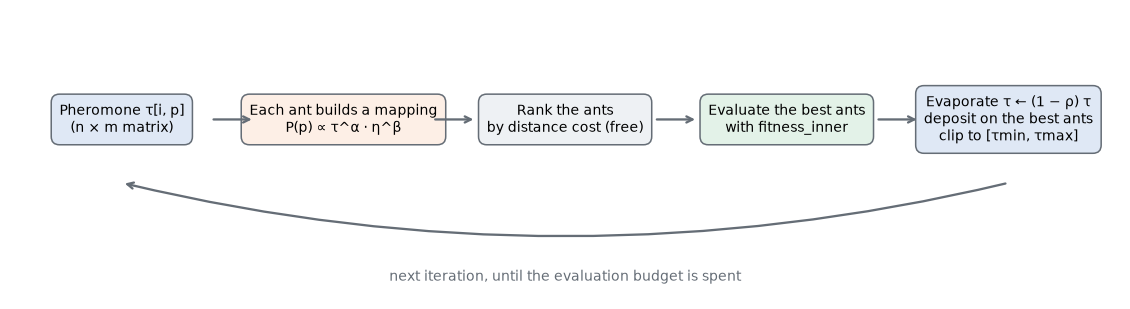

In [5]:
def plot_aco_cycle():
    """Schéma des étapes d'une itération de la colonie, avec la flèche de retour vers l'itération suivante."""
    fig, ax = plt.subplots(figsize=(13, 3.4))
    # Texte et couleur de fond de chaque étape.
    boxes = [
        ("Pheromone τ[i, p]\n(n × m matrix)", PHYSICAL_SOFT),
        ("Each ant builds a mapping\nP(p) ∝ τ^α · η^β", LOGICAL_SOFT),
        ("Rank the ants\nby distance cost (free)", "#eef1f4"),
        ("Evaluate the best ants\nwith fitness_inner", "#e3f2e8"),
        ("Evaporate τ ← (1 − ρ) τ\ndeposit on the best ants\nclip to [τmin, τmax]", PHYSICAL_SOFT),
    ]
    # Positions horizontales régulières des boîtes (en fraction de la largeur).
    xs = np.linspace(0.1, 0.9, len(boxes))
    for x, (text, color) in zip(xs, boxes):
        ax.text(x, 0.62, text, ha="center", va="center", fontsize=9, transform=ax.transAxes, bbox={"boxstyle": "round,pad=0.6", "fc": color, "ec": MUTED})
    # Flèches entre boîtes successives.
    for a, b in zip(xs[:-1], xs[1:]):
        ax.annotate("", xy=(b - 0.08, 0.62), xytext=(a + 0.08, 0.62), xycoords="axes fraction", arrowprops={"arrowstyle": "->", "color": MUTED, "lw": 1.5})
    # Flèche de retour (courbée vers le bas) de la dernière étape vers la première.
    ax.annotate("", xy=(xs[0], 0.4), xytext=(xs[-1], 0.4), xycoords="axes fraction", arrowprops={"arrowstyle": "->", "color": MUTED, "lw": 1.5, "connectionstyle": "arc3,rad=-0.12"})
    ax.text(0.5, 0.06, "next iteration, until the evaluation budget is spent", ha="center", transform=ax.transAxes, color=MUTED, fontsize=9)
    ax.set_axis_off()
    return fig


plot_aco_cycle();

## 1. Anatomie d'une fourmi

On construit un placement sur l'instance choisie avec des phéromones **uniformes** (comme à la première itération) : seule l'heuristique guide les choix.

### Ordre de placement

In [6]:
instance = load_instance(INSTANCE_ID)
coordinates = np.array(hardware.coordinates(instance.m, instance.edges), dtype=float)
# Colonie avec les réglages de référence (ordre de placement et heuristique).
colony = ant_colony.Colony(instance, BASE["alpha"], BASE["beta"])
tau_min, tau_max = ant_colony.pheromone_bounds(BASE["rho"], BASE["tau_min_ratio"])
# Phéromones uniformes (toutes au maximum), comme au début d'une exécution.
uniform = np.full((instance.n, instance.m), tau_max)
# Construction d'une fourmi en gardant le détail de chaque étape (record=True).
demo_mapping, demo_steps = colony.construct(uniform, np.random.default_rng(SEED), record=True)

# Tableau de l'ordre de placement : pour chaque étape, le qubit placé et ses liens avec les qubits déjà placés.
order_table = pd.DataFrame({
    "step": range(1, instance.n + 1),
    "logical qubit": [f"q{q}" for q in colony.order],
    "gates with already placed qubits": [int(colony.weights[q, colony.order[:k]].sum()) for k, q in enumerate(colony.order)],
    "total 2-qubit gates": [int(colony.weights[q].sum()) for q in colony.order],
    "chosen physical qubit": [f"P{demo_mapping[q]}" for q in colony.order],
})
order_table

,step,logical qubit,gates with already placed qubits,total 2-qubit gates,chosen physical qubit
0,1,q0,0,4,P12
1,2,q10,2,4,P7
2,3,q11,2,4,P4
3,4,q3,2,4,P1
4,5,q2,2,4,P6
5,6,q13,4,4,P14
6,7,q1,0,4,P13
7,8,q9,2,4,P18
8,9,q8,2,4,P17
9,10,q12,4,4,P19


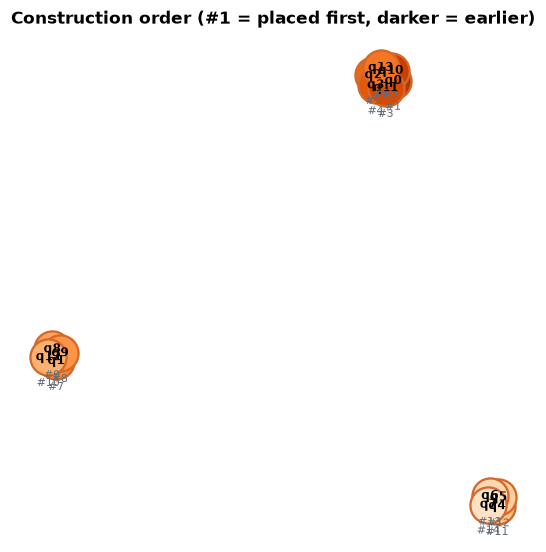

In [7]:
def plot_construction_order(instance, colony, seed=0):
    """Graphe d'interaction où chaque sommet porte son rang dans l'ordre de placement (#1 = placé en premier)."""
    graph = nx.Graph()
    graph.add_nodes_from(range(instance.n))
    graph.add_edges_from(map(tuple, instance.pairs))
    positions = nx.spring_layout(graph, seed=seed, k=1.8 / math.sqrt(instance.n), iterations=500)
    # Rang de chaque qubit dans l'ordre de construction.
    rank = {q: k + 1 for k, q in enumerate(colony.order)}
    max_weight = max(int(instance.weights.max()), 1)
    fig, ax = plt.subplots(figsize=(7, 6))
    for (a, b), weight in zip(instance.pairs, instance.weights):
        (xa, ya), (xb, yb) = positions[a], positions[b]
        ax.plot([xa, xb], [ya, yb], color=GRID, linewidth=1 + 3 * math.sqrt(weight / max_weight), zorder=1)
    # Plus le qubit est placé tôt, plus sa couleur est foncée.
    cmap = plt.get_cmap("Oranges_r")
    for q, (x, y) in positions.items():
        ax.scatter(x, y, s=560, color=cmap(0.15 + 0.7 * (rank[q] - 1) / max(instance.n - 1, 1)), edgecolors=LOGICAL, linewidths=1.5, zorder=2)
        ax.text(x, y, f"q{q}", ha="center", va="center", fontsize=8, fontweight="bold", zorder=3)
        ax.annotate(f"#{rank[q]}", (x, y), xytext=(0, -19), textcoords="offset points", ha="center", fontsize=7, color=MUTED, zorder=3)
    ax.set_title("Construction order (#1 = placed first, darker = earlier)")
    ax.set_aspect("equal")
    ax.margins(0.08)
    ax.set_axis_off()
    return fig


plot_construction_order(instance, colony);

### Les choix pas à pas

Chaque panneau montre une étape de la construction : les qubits physiques déjà occupés portent leur qubit logique, les autres sont colorés selon la **probabilité** d'être choisis à cette étape (valeur affichée). Le cercle noir marque le choix effectivement tiré. Au début, l'heuristique favorise les qubits centraux ; ensuite, elle attire vers les voisins des partenaires déjà placés.

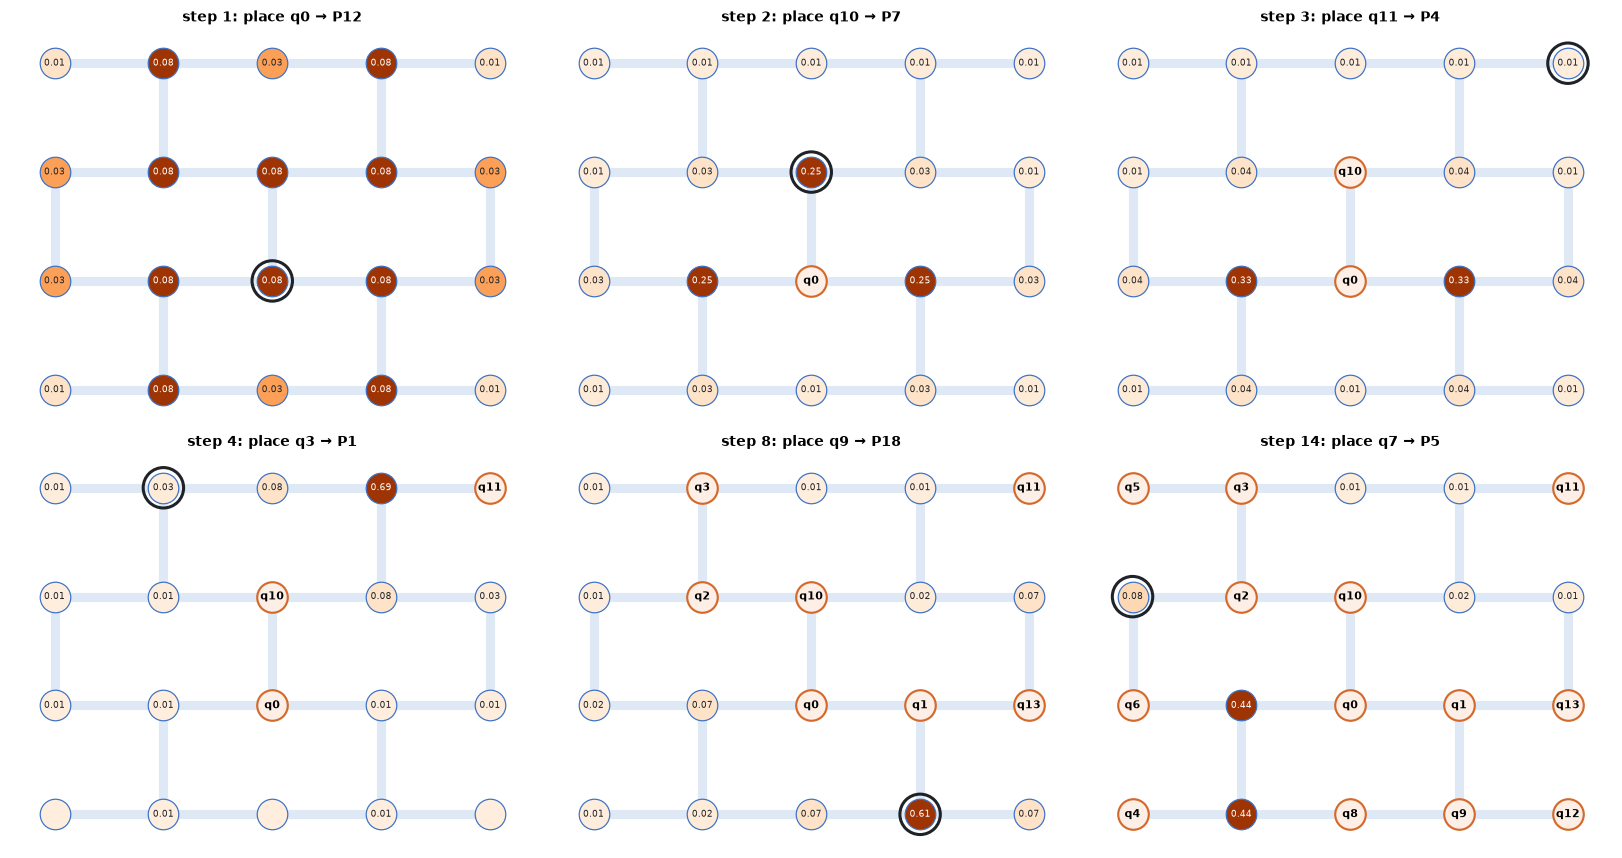

In [8]:
def curve_points(start, end, bend):
    """Points d'une courbe (Bézier quadratique) entre deux positions, décalée de `bend` sur le côté."""
    start, end = np.asarray(start), np.asarray(end)
    direction = end - start
    normal = np.array([-direction[1], direction[0]]) / (np.linalg.norm(direction) or 1)
    control = (start + end) / 2 + normal * bend
    t = np.linspace(0, 1, 30)[:, None]
    return (1 - t) ** 2 * start + 2 * (1 - t) * t * control + t ** 2 * end


def draw_chip(ax, instance, coordinates, mapping=None, values=None, chosen=None, show_interactions=False, title=""):
    """Dessine la puce sur l'axe `ax`.

    - mapping : placement à afficher (les valeurs -1 = qubits pas encore placés) ;
    - values : une valeur par qubit physique libre (par ex. une probabilité), affichée en couleur ;
    - chosen : qubit physique entouré en noir ;
    - show_interactions : superpose les interactions du circuit, colorées selon la distance.
    """
    # Connexions physiques de la puce.
    for a, b in instance.edges:
        ax.plot(*coordinates[[a, b]].T, color=PHYSICAL_SOFT, linewidth=6, solid_capstyle="round", zorder=1)
    # Qubit physique -> qubit logique qui l'occupe (seulement les qubits déjà placés).
    owner = {} if mapping is None else {int(p): q for q, p in enumerate(mapping) if p >= 0}
    if show_interactions and mapping is not None:
        max_weight = max(int(instance.weights.max()), 1)
        for index, ((a, b), weight) in enumerate(zip(instance.pairs, instance.weights)):
            pa, pb = mapping[a], mapping[b]
            distance = instance.distances[pa, pb]
            width = 0.8 + 2 * math.sqrt(weight / max_weight)
            if distance == 1:
                ax.plot(*coordinates[[pa, pb]].T, color=distance_color(1), linewidth=width, zorder=2)
            else:
                # Courbe pour ne pas passer sur les qubits intermédiaires.
                bend = (0.3 if index % 2 else -0.3) * min(np.linalg.norm(coordinates[pb] - coordinates[pa]), 3)
                points = curve_points(coordinates[pa], coordinates[pb], bend)
                ax.plot(points[:, 0], points[:, 1], color=distance_color(distance), linewidth=width, linestyle=(0, (3, 2)), zorder=2)
    cmap = plt.get_cmap("Oranges")
    # Valeur maximale, pour normaliser les couleurs.
    top = values.max() if values is not None and values.max() > 0 else 1.0
    for p, (x, y) in enumerate(coordinates):
        if p in owner:
            # Qubit occupé : disque orange clair avec le qubit logique.
            ax.scatter(x, y, s=400, color=LOGICAL_SOFT, edgecolors=LOGICAL, linewidths=1.4, zorder=3)
            ax.text(x, y, f"q{owner[p]}", ha="center", va="center", fontsize=7, fontweight="bold", zorder=4)
        elif values is not None:
            # Qubit libre coloré selon sa valeur (probabilité), valeur écrite si elle n'est pas négligeable.
            ax.scatter(x, y, s=400, color=cmap(0.05 + 0.85 * values[p] / top), edgecolors=PHYSICAL, linewidths=0.8, zorder=3)
            ax.text(x, y, f"{values[p]:.2f}" if values[p] >= 0.005 else "", ha="center", va="center", fontsize=6, color="white" if values[p] > 0.6 * top else "#1f2328", zorder=4)
        else:
            # Qubit libre sans valeur : cercle blanc en pointillés avec son numéro.
            ax.scatter(x, y, s=260, color="white", edgecolors=PHYSICAL, linewidths=1, linestyle="--", zorder=3)
            ax.text(x, y, str(p), ha="center", va="center", fontsize=6, color=PHYSICAL, zorder=4)
        if chosen == p:
            ax.scatter(x, y, s=700, facecolors="none", edgecolors="#1f2328", linewidths=2, zorder=5)
    ax.set_title(title, fontsize=9)
    ax.invert_yaxis()
    ax.set_aspect("equal")
    ax.margins(0.1)
    ax.set_axis_off()


def plot_construction_steps(instance, coordinates, steps, indices):
    """Une puce par étape choisie, colorée selon les probabilités de choix à cette étape."""
    width = np.ptp(coordinates[:, 0]) + 1
    height = np.ptp(coordinates[:, 1]) + 1
    fig, axes = subplot_grid(len(indices), cols=3, width=0.75 * width + 1.2, height=0.75 * height + 1.0)
    for ax, index in zip(axes, indices):
        step = steps[index]
        # Probabilité de chaque qubit physique (0 pour les qubits déjà occupés).
        values = np.zeros(instance.m)
        values[step["free"]] = step["probabilities"]
        draw_chip(ax, instance, coordinates, mapping=step["mapping"], values=values, chosen=step["choice"], title=f"step {index + 1}: place q{step['qubit']} → P{step['choice']}")
    fig.tight_layout()
    return fig


# Étapes montrées : les 4 premières, celle du milieu et la dernière.
shown = sorted({0, 1, 2, 3, instance.n // 2, instance.n - 1})
plot_construction_steps(instance, coordinates, demo_steps, shown);

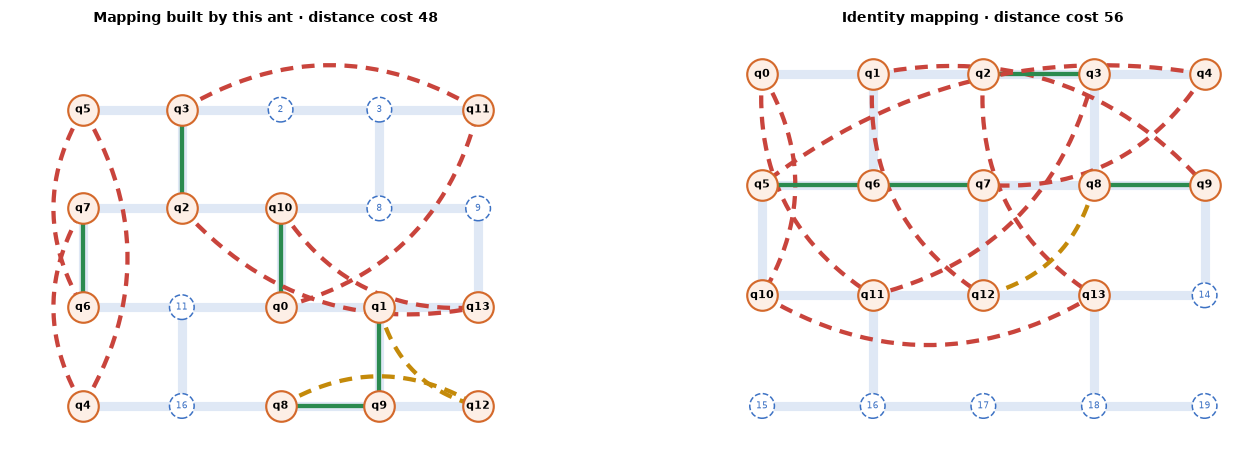

In [9]:
# Le placement construit par cette fourmi, comparé au placement identité.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
draw_chip(axes[0], instance, coordinates, mapping=demo_mapping, show_interactions=True, title=f"Mapping built by this ant · distance cost {distance_cost(instance, demo_mapping)}")
draw_chip(axes[1], instance, coordinates, mapping=list(range(instance.n)), show_interactions=True, title=f"Identity mapping · distance cost {distance_cost(instance, list(range(instance.n)))}")
fig.tight_layout()

## 2. Une exécution complète

La colonie de référence (`BASE`) tourne sur l'instance choisie avec le budget complet. L'algorithme enregistre son état à chaque itération (`result.trace`) : coûts des fourmis évaluées, diversité, phéromones.

In [10]:
# Une seule exécution (relue depuis results/ si elle existe déjà).
single = cached_grid(f"single_run_instance_{INSTANCE_ID}", {"ant_colony": (ant_colony.run, BASE)}, [INSTANCE_ID], [SEED], BUDGET)[0]
iterations = iterations_frame(single)
print(f"best fitness {single.best_cost} after {single.evaluations} evaluations ({len(iterations)} iterations, {single.seconds:.1f} s)")
# Indicateurs par itération (la colonne des coûts individuels, qui contient des listes, n'est pas affichée).
iterations_table = iterations[["iteration", "evaluations", "iteration_best", "iteration_mean", "global_best", "surrogate_min", "unique_ants", "diversity", "entropy"]].round(3)
iterations_table

Loaded 1 runs from C:\Users\hugo-\Desktop\Projet-GOC\results\ant_colony\single_run_instance_6.jsonl
best fitness 25 after 200 evaluations (40 iterations, 7.5 s)


,iteration,evaluations,iteration_best,iteration_mean,global_best,surrogate_min,unique_ants,diversity,entropy
0,1,5,32,48.2,32,8,30,0.944,1.000
1,2,10,32,37.2,32,8,30,0.945,0.997
2,3,15,28,40.8,28,12,30,0.939,0.994
3,4,20,36,43.4,28,8,30,0.940,0.989
4,5,25,32,46.2,28,12,30,0.936,0.981
5,6,30,33,51.8,28,12,30,0.933,0.971
6,7,35,25,38.0,25,16,30,0.937,0.961
7,8,40,32,47.4,25,12,30,0.925,0.946
8,9,45,28,42.2,25,8,30,0.907,0.927
9,10,50,32,45.6,25,16,30,0.920,0.904


**Lecture des trois graphiques :**
- **gauche** : chaque point est une fourmi évaluée. Si la colonie apprend, le nuage descend au fil des itérations ;
- **milieu** : coût de distance des fourmis construites (toutes, y compris celles non évaluées) ; il baisse quand les phéromones guident vers de bonnes zones ;
- **droite** : la **diversité** (part moyenne de qubits placés différemment entre deux fourmis) et l'**entropie** des phéromones (1 = aucune préférence, 0 = choix figés). Les deux baissent quand la colonie converge ; si elles chutent trop vite, la colonie risque de se figer sur une mauvaise solution.

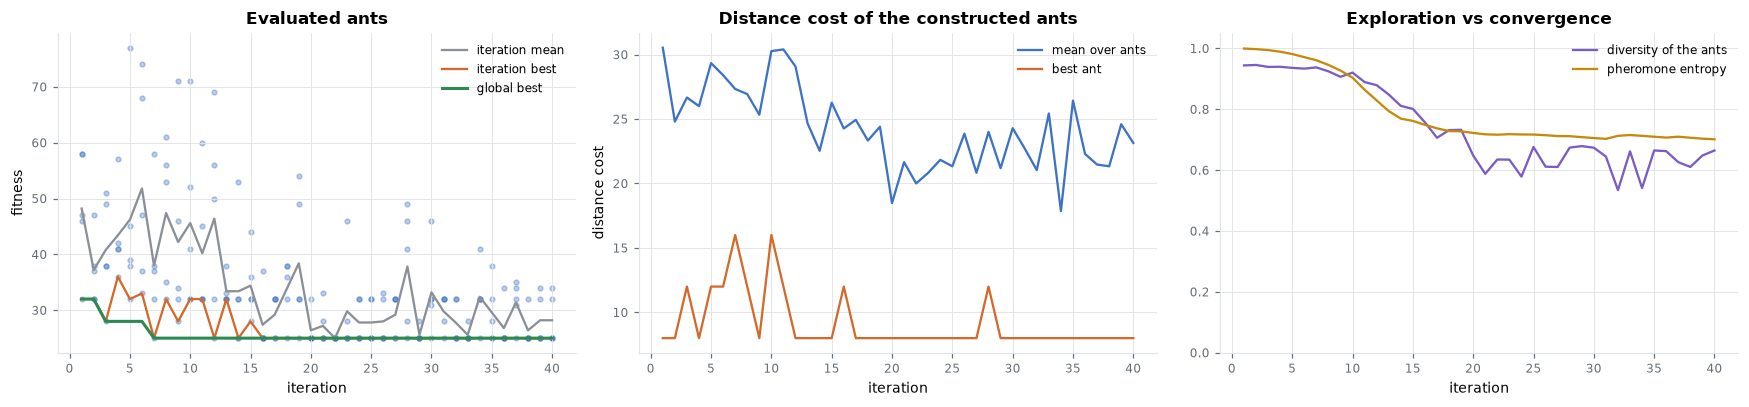

In [11]:
def plot_colony_progress(result):
    """Trois graphiques de suivi : fourmis évaluées, coût de distance des fourmis, diversité et entropie."""
    frame = iterations_frame(result)
    fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
    ax = axes[0]
    # Un point par fourmi évaluée, à l'abscisse de son itération.
    for _, row in frame.iterrows():
        ax.scatter([row["iteration"]] * len(row["costs"]), row["costs"], s=10, color=PHYSICAL, alpha=0.35)
    ax.plot(frame["iteration"], frame["iteration_mean"], color=PALETTE[5], label="iteration mean")
    ax.plot(frame["iteration"], frame["iteration_best"], color=LOGICAL, label="iteration best")
    ax.plot(frame["iteration"], frame["global_best"], color=DISTANCE_COLORS[1], linewidth=2, label="global best")
    ax.set_xlabel("iteration")
    ax.set_ylabel("fitness")
    ax.set_title("Evaluated ants")
    ax.legend()
    axes[1].plot(frame["iteration"], frame["surrogate_mean"], color=PALETTE[0], label="mean over ants")
    axes[1].plot(frame["iteration"], frame["surrogate_min"], color=PALETTE[1], label="best ant")
    axes[1].set_xlabel("iteration")
    axes[1].set_ylabel("distance cost")
    axes[1].set_title("Distance cost of the constructed ants")
    axes[1].legend()
    axes[2].plot(frame["iteration"], frame["diversity"], color=PALETTE[4], label="diversity of the ants")
    axes[2].plot(frame["iteration"], frame["entropy"], color=PALETTE[6], label="pheromone entropy")
    axes[2].set_ylim(0, 1.05)
    axes[2].set_xlabel("iteration")
    axes[2].set_title("Exploration vs convergence")
    axes[2].legend()
    fig.tight_layout()
    return fig


plot_colony_progress(single);

### Évolution des phéromones

Chaque panneau est la matrice des phéromones à une itération, normalisée par ligne : la case (i, p) donne la probabilité « mémoire » de placer *q_i* sur *P_p*. Les carrés bleus marquent le meilleur placement final. Au départ tout est uniforme ; au fil des itérations, chaque ligne se concentre sur quelques qubits physiques.

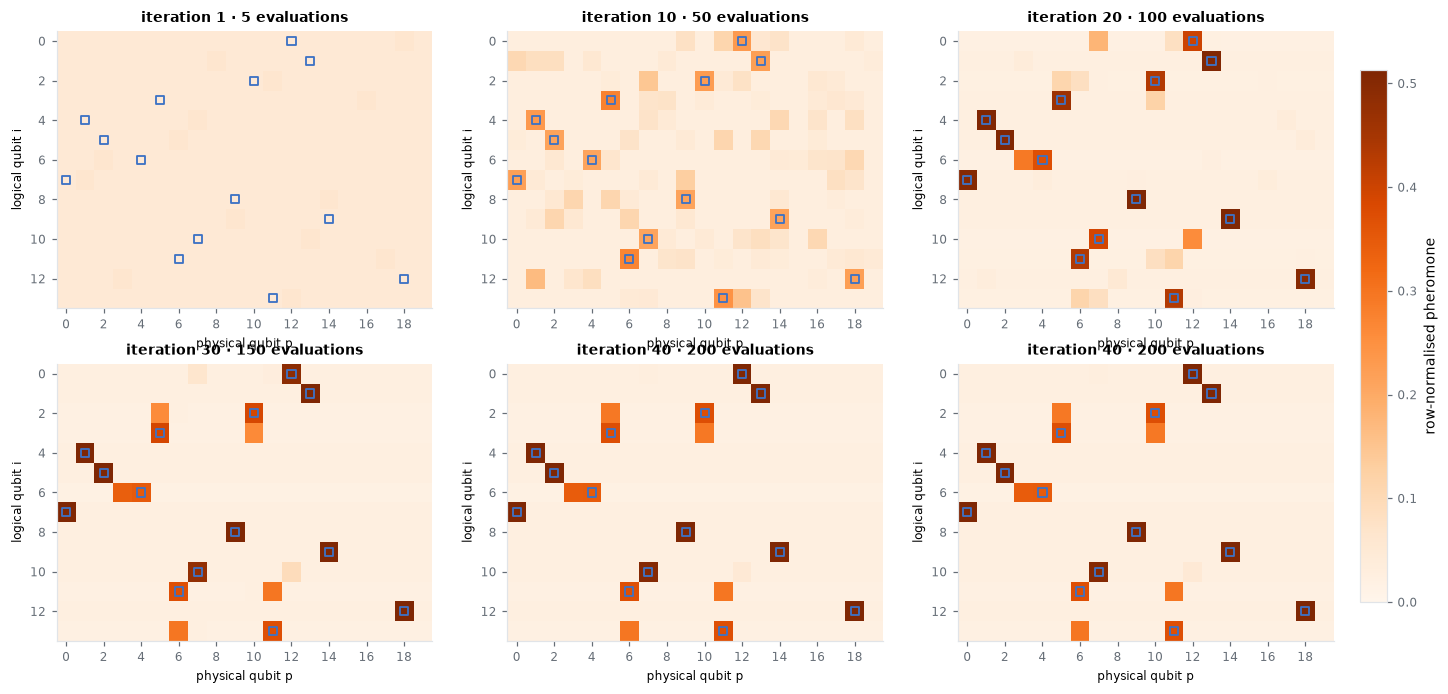

In [12]:
def plot_pheromone_snapshots(result, panels=6):
    """Matrices de phéromones à plusieurs moments de l'exécution, normalisées par ligne, avec le meilleur placement final."""
    snapshots = result.trace["snapshots"]
    # Jusqu'à panels − 1 copies réparties régulièrement, plus l'état final.
    chosen = [snapshots[int(k)] for k in np.unique(np.linspace(0, len(snapshots) - 1, min(panels - 1, len(snapshots))).astype(int))]
    chosen.append({"iteration": len(result.trace["iterations"]), "evaluations": result.evaluations, "pheromone": result.trace["pheromone"]})
    # Normalisation par ligne : chaque ligne devient une distribution de probabilités.
    matrices = [np.array(s["pheromone"]) / np.array(s["pheromone"]).sum(axis=1, keepdims=True) for s in chosen]
    # Même échelle de couleurs pour tous les panneaux.
    top = max(m.max() for m in matrices)
    best = result.trace["best_mapping"]
    fig, axes = subplot_grid(len(chosen), cols=3, width=5.2, height=3.6)
    for ax, snapshot, matrix in zip(axes, chosen, matrices):
        image = ax.imshow(matrix, cmap="Oranges", vmin=0, vmax=top, aspect="auto")
        # Carrés bleus : case (i, meilleur placement de i).
        ax.scatter(best, range(len(best)), marker="s", s=28, facecolors="none", edgecolors=PHYSICAL, linewidths=1.2)
        ax.set_title(f"iteration {snapshot['iteration']} · {snapshot['evaluations']} evaluations", fontsize=9)
        ax.set_xlabel("physical qubit p", fontsize=8)
        ax.set_ylabel("logical qubit i", fontsize=8)
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
        ax.grid(False)
    fig.colorbar(image, ax=list(axes), fraction=0.02, pad=0.02, label="row-normalised pheromone")
    return fig


plot_pheromone_snapshots(single);

### Ce que la colonie a appris

- **Meilleur placement** : le meilleur placement évalué pendant l'exécution.
- **Placement des phéromones** : on lit directement la matrice finale, en attribuant à chaque qubit logique le qubit physique de plus forte phéromone (sans doublon). C'est la « solution consensuelle » de la colonie.

Les deux sont réévalués `REEVALUATIONS` fois avec l'identité comme référence, pour juger hors du bruit d'une évaluation unique.

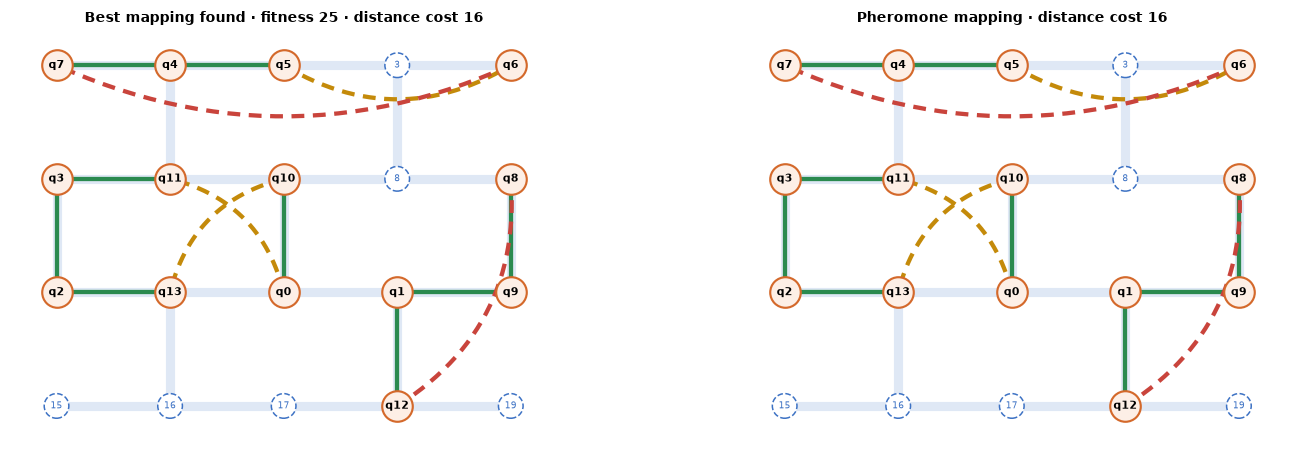

In [13]:
# Placement « consensus » lu dans la matrice finale des phéromones.
learned = ant_colony.pheromone_mapping(single.trace["pheromone"])
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
draw_chip(axes[0], instance, coordinates, mapping=single.best_mapping, show_interactions=True, title=f"Best mapping found · fitness {single.best_cost} · distance cost {distance_cost(instance, single.best_mapping)}")
draw_chip(axes[1], instance, coordinates, mapping=learned, show_interactions=True, title=f"Pheromone mapping · distance cost {distance_cost(instance, learned)}")
fig.tight_layout()

In [14]:
# Réévaluation de trois placements pour les comparer hors du bruit d'une seule évaluation.
checker = Problem(instance)
candidates = {"best mapping found": single.best_mapping, "pheromone mapping": learned, "identity": list(range(instance.n))}
rows = []
for label, mapping in candidates.items():
    costs = checker.fitness_samples(mapping, REEVALUATIONS)
    rows.append({"mapping": label, "distance cost": distance_cost(instance, mapping), "min": min(costs), "mean": round(float(np.mean(costs)), 2), "max": max(costs), "std": round(float(np.std(costs)), 2)})
check_table = pd.DataFrame(rows).set_index("mapping")
check_table

,distance cost,min,mean,max,std
mapping,,,,,
best mapping found,16,25,25.0,25,0.00
pheromone mapping,16,25,25.0,25,0.00
identity,56,83,93.5,98,6.87


## 3. Effet des paramètres

Chaque étude fait varier **un seul** paramètre autour de `BASE`, sur deux instances choisies pour leurs profils opposés (notebook 02) : l'instance **3** (QFT, coût de distance peu fiable) et l'instance **9** (GHZ en chaîne, coût de distance très fiable). Chaque réglage est lancé avec plusieurs graines, à budget égal.

En haut : le meilleur coût final (une boîte = les graines). En bas : la convergence moyenne.

In [15]:
def plot_study(results, title):
    """Pour chaque instance : boîtes du meilleur coût final (en haut) et convergence moyenne (en bas), par réglage."""
    frame = results_frame(results)
    # Ordre des réglages tel qu'ils ont été définis.
    order = list(dict.fromkeys(r.algorithm for r in results))
    instance_ids = sorted(frame["instance_id"].unique())
    fig, axes = plt.subplots(2, len(instance_ids), figsize=(5.4 * len(instance_ids), 6.6), squeeze=False)
    for col, instance_id in enumerate(instance_ids):
        subset = frame[frame["instance_id"] == instance_id]
        ax = axes[0, col]
        ax.boxplot([subset.loc[subset["algorithm"] == a, "best_cost"] for a in order], widths=0.5, medianprops={"color": LOGICAL})
        ax.set_xticks(range(1, len(order) + 1), order, fontsize=8)
        ax.set_title(f"Instance {instance_id} · final best fitness")
        history = history_frame([r for r in results if r.instance_id == instance_id])
        ax = axes[1, col]
        for color, algorithm in zip(PALETTE, order):
            curves = history[history["algorithm"] == algorithm].pivot_table(index="evaluation", columns="seed", values="best").ffill()
            ax.plot(curves.index, curves.mean(axis=1), color=color, label=algorithm, linewidth=1.5)
        ax.set_title(f"Instance {instance_id} · mean convergence")
        ax.set_xlabel("evaluations", fontsize=8)
        ax.set_ylabel("best fitness so far", fontsize=8)
        ax.legend()
    fig.suptitle(title, y=1.0)
    fig.tight_layout()
    return fig


def study(name, values, build):
    """Lance une étude : un réglage par valeur, obtenu en modifiant BASE avec build(valeur)."""
    algorithms = {label: (ant_colony.run, {**BASE, **NO_SNAPSHOTS, **build(value)}) for label, value in values.items()}
    return cached_grid(f"study_{name}", algorithms, STUDY_INSTANCES, STUDY_SEEDS, BUDGET)

### 3.1 Poids de l'heuristique β

β = 0 : les fourmis ignorent la géométrie de la puce et ne suivent que les phéromones. Plus β est grand, plus elles se rapprochent d'une construction gloutonne sur les distances.

Loaded 24 runs from C:\Users\hugo-\Desktop\Projet-GOC\results\ant_colony\study_beta.jsonl


instance_id,inst. 3,inst. 9
algorithm,,
beta=0,135.3 ± 4.8 (131),95.3 ± 6.5 (87)
beta=1,132.0 ± 2.4 (129),70.3 ± 1.9 (69)
beta=2,130.3 ± 5.7 (123),56.3 ± 7.1 (49)
beta=4,136.7 ± 7.6 (126),53.0 ± 0.8 (52)


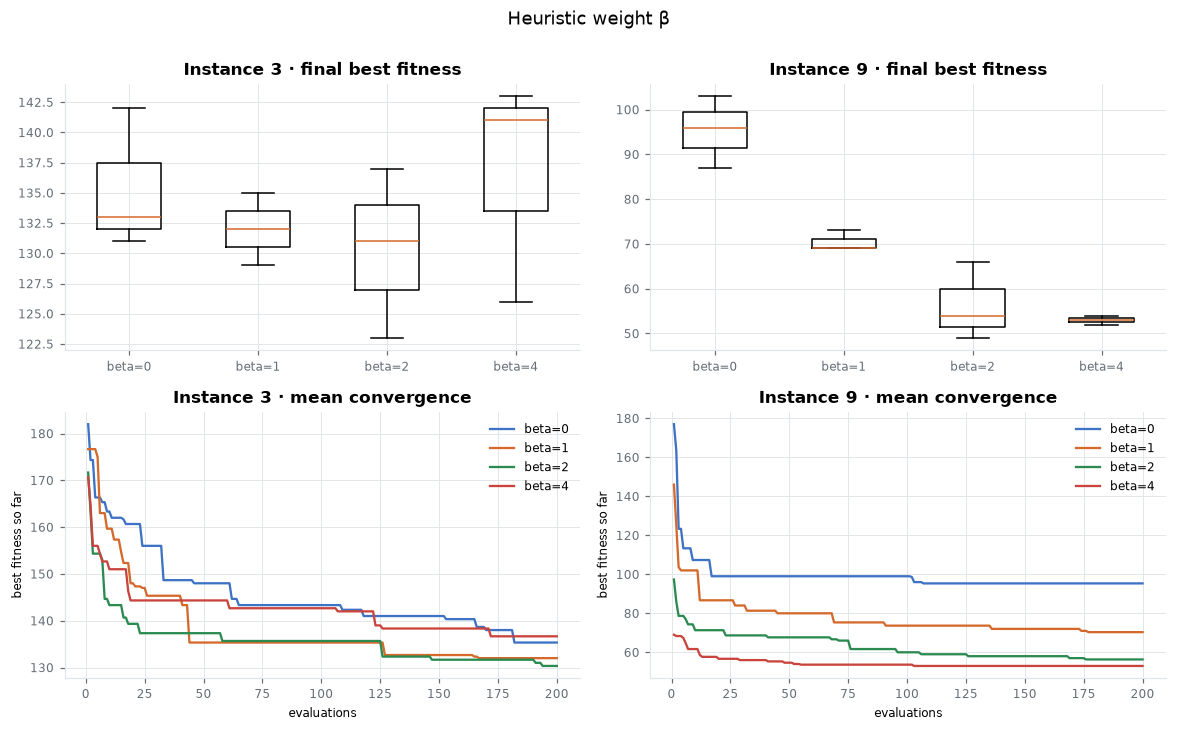

In [16]:
beta_study = study("beta", {"beta=0": 0.0, "beta=1": 1.0, "beta=2": 2.0, "beta=4": 4.0}, lambda v: {"beta": v})
beta_table = display_table(results_frame(beta_study))
display(beta_table)
plot_study(beta_study, "Heuristic weight β");

### 3.2 Évaporation ρ

ρ petit : mémoire longue, apprentissage lent mais prudent. ρ grand : la colonie oublie vite et se concentre rapidement sur les meilleures solutions récentes (τ_max = 1/ρ change aussi).

Loaded 24 runs from C:\Users\hugo-\Desktop\Projet-GOC\results\ant_colony\study_rho.jsonl


instance_id,inst. 3,inst. 9
algorithm,,
rho=0.05,132.3 ± 5.9 (124),64.0 ± 1.4 (63)
rho=0.1,125.7 ± 4.5 (122),58.0 ± 4.5 (53)
rho=0.2,122.3 ± 5.0 (117),52.0 ± 3.7 (48)
rho=0.4,132.3 ± 4.0 (129),62.0 ± 7.1 (56)


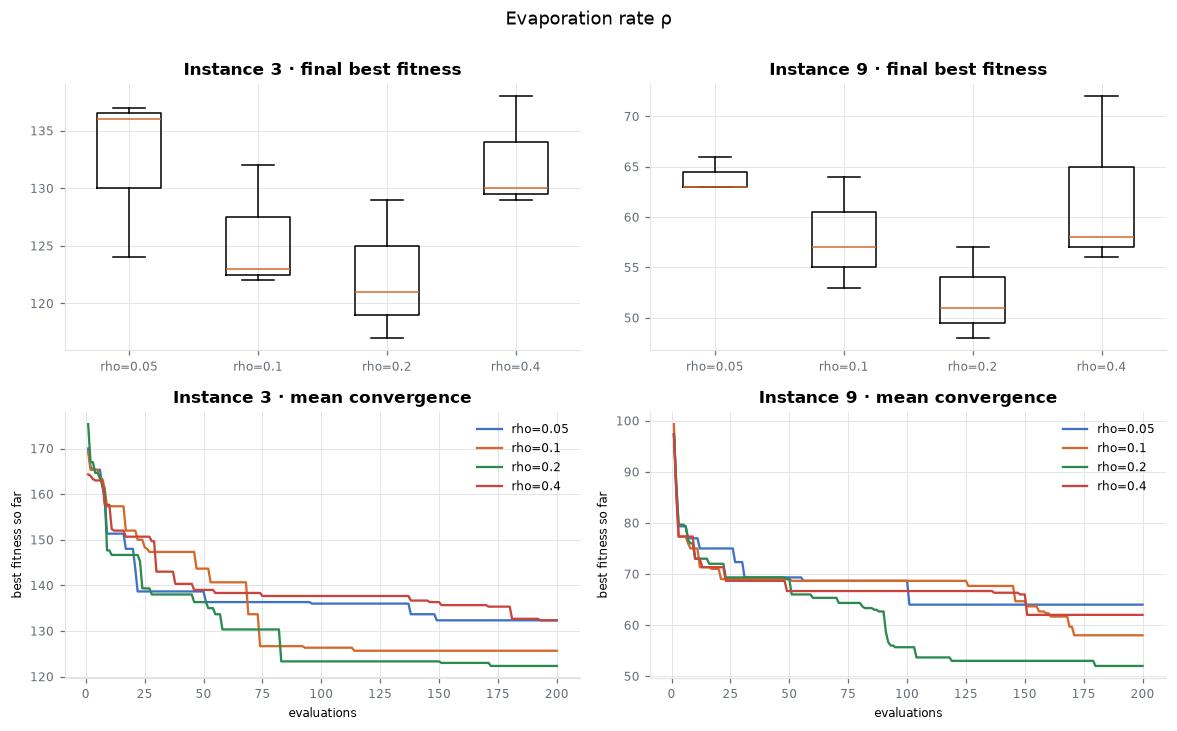

In [17]:
rho_study = study("rho", {"rho=0.05": 0.05, "rho=0.1": 0.1, "rho=0.2": 0.2, "rho=0.4": 0.4}, lambda v: {"rho": v})
rho_table = display_table(results_frame(rho_study))
display(rho_table)
plot_study(rho_study, "Evaporation rate ρ");

### 3.3 Taille de la colonie et filtrage par coût de distance

`fourmis/évaluées` : `10/10` et `20/20` évaluent toutes les fourmis avec la vraie fitness ; `30/5` et `60/5` construisent beaucoup de fourmis mais n'évaluent que les 5 meilleures selon le coût de distance. À budget égal, le filtrage permet beaucoup plus d'itérations.

Loaded 24 runs from C:\Users\hugo-\Desktop\Projet-GOC\results\ant_colony\study_colony.jsonl


instance_id,inst. 3,inst. 9
algorithm,,
10/10,131.3 ± 4.5 (126),72.3 ± 4.5 (66)
20/20,139.0 ± 5.0 (135),68.0 ± 8.3 (57)
30/5,129.3 ± 7.1 (122),55.0 ± 2.9 (52)
60/5,124.0 ± 0.8 (123),53.3 ± 2.6 (51)


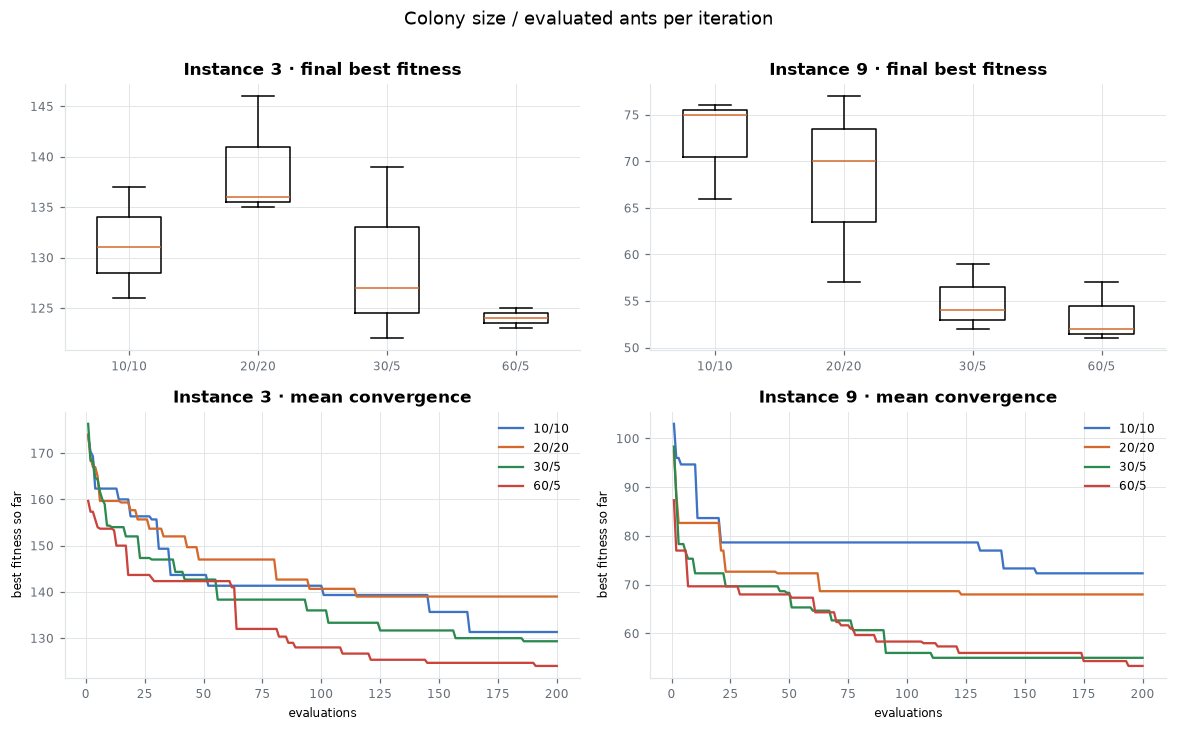

In [18]:
colony_study = study("colony", {"10/10": (10, 10), "20/20": (20, 20), "30/5": (30, 5), "60/5": (60, 5)}, lambda v: {"ants": v[0], "evaluated": v[1]})
colony_table = display_table(results_frame(colony_study))
display(colony_table)
plot_study(colony_study, "Colony size / evaluated ants per iteration");

### 3.4 Recherche locale sur le coût de distance

Chaque fourmi construite est améliorée par une descente de *k* échanges sur le coût de distance (gratuite) avant le classement. C'est un **hybride** : colonie de fourmis + recherche locale.

Loaded 24 runs from C:\Users\hugo-\Desktop\Projet-GOC\results\ant_colony\study_local_search.jsonl


instance_id,inst. 3,inst. 9
algorithm,,
ls=0,133.3 ± 6.0 (125),52.7 ± 2.6 (49)
ls=50,134.3 ± 4.8 (130),50.7 ± 1.2 (49)
ls=200,135.3 ± 7.5 (130),53.7 ± 3.7 (49)
ls=1000,136.3 ± 1.2 (135),49.7 ± 3.3 (45)


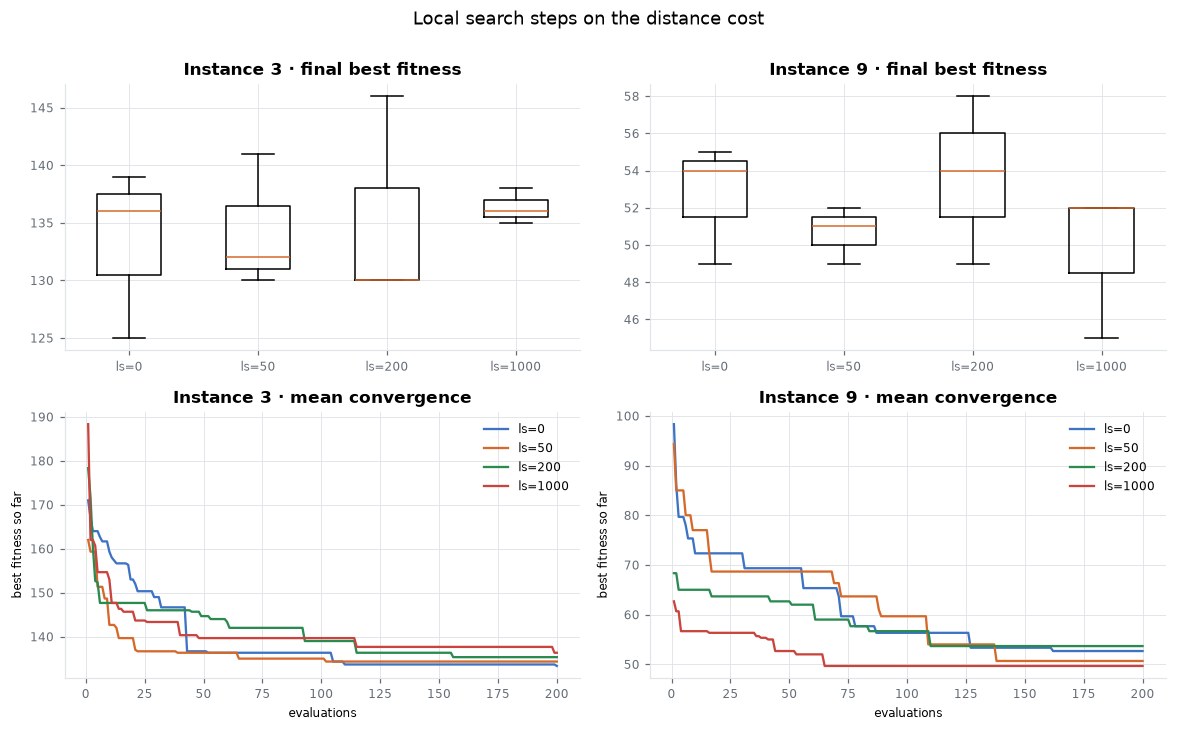

In [19]:
local_study = study("local_search", {"ls=0": 0, "ls=50": 50, "ls=200": 200, "ls=1000": 1000}, lambda v: {"local_search_steps": v})
local_table = display_table(results_frame(local_study))
display(local_table)
plot_study(local_study, "Local search steps on the distance cost");

## 4. Comparaison avec les références, sur toutes les instances

Même budget pour tous, plusieurs graines par algorithme et par instance.

| Algorithme | Description |
|---|---|
| `identity` | placement identité réévalué à chaque fois (minimum de N tirages du bruit) |
| `random_search` | placements aléatoires |
| `surrogate_filtered` | le meilleur de 200 placements aléatoires selon le coût de distance, puis vraie évaluation |
| `aco_all` | colonie de 10 fourmis, toutes évaluées |
| `aco_filtered` | colonie `BASE` : 30 fourmis, les 5 meilleures selon le coût de distance sont évaluées |
| `aco_filtered_ls` | comme `aco_filtered` + recherche locale de 200 échanges sur chaque fourmi |

In [20]:
# Les six algorithmes comparés, avec leurs paramètres.
COMPARISON = {
    "identity": (identity.run, {}),
    "random_search": (random_search.run, {}),
    "surrogate_filtered": (surrogate_filtered.run, {"candidates": 200}),
    "aco_all": (ant_colony.run, {**BASE, **NO_SNAPSHOTS, "ants": 10, "evaluated": 10}),
    "aco_filtered": (ant_colony.run, {**BASE, **NO_SNAPSHOTS}),
    "aco_filtered_ls": (ant_colony.run, {**BASE, **NO_SNAPSHOTS, "local_search_steps": 200}),
}
comparison = cached_grid("comparison", COMPARISON, COMPARISON_INSTANCES, SEEDS, BUDGET)
# Une ligne par exécution.
frame = results_frame(comparison)
# Ordre d'affichage des algorithmes.
ORDER = list(COMPARISON)

Loaded 270 runs from C:\Users\hugo-\Desktop\Projet-GOC\results\ant_colony\comparison.jsonl


**Tableau comparatif** : `moyenne ± écart-type (meilleur)` du meilleur coût trouvé sur les graines.

In [21]:
summary_table = display_table(frame).reindex(ORDER)
summary_table

instance_id,inst. 1,inst. 2,inst. 3,inst. 4,inst. 5,inst. 6,inst. 7,inst. 8,inst. 9
algorithm,,,,,,,,,
identity,57.0 ± 0.0 (57),59.0 ± 0.0 (59),141.0 ± 0.0 (141),62.0 ± 0.0 (62),332.2 ± 1.0 (331),78.2 ± 2.4 (77),107.0 ± 0.0 (107),66.8 ± 1.0 (66),137.0 ± 0.0 (137)
random_search,38.4 ± 2.1 (36),90.2 ± 4.5 (86),139.4 ± 5.2 (132),42.4 ± 0.8 (42),334.0 ± 9.0 (323),39.6 ± 3.7 (35),73.6 ± 7.2 (63),40.0 ± 3.8 (34),98.2 ± 3.5 (93)
surrogate_filtered,34.8 ± 1.7 (33),75.8 ± 2.9 (71),140.0 ± 2.2 (137),38.8 ± 1.5 (36),332.0 ± 4.9 (326),33.8 ± 2.1 (31),64.6 ± 6.3 (57),38.4 ± 2.4 (34),90.2 ± 10.4 (79)
aco_all,28.6 ± 2.9 (25),59.0 ± 0.0 (59),131.0 ± 3.7 (124),36.2 ± 1.0 (35),324.8 ± 2.9 (320),25.6 ± 1.2 (25),39.8 ± 5.9 (34),25.8 ± 3.9 (22),69.8 ± 6.4 (59)
aco_filtered,30.0 ± 0.9 (29),59.0 ± 0.0 (59),128.0 ± 5.2 (122),33.8 ± 2.4 (30),323.0 ± 4.4 (317),25.0 ± 0.0 (25),25.2 ± 2.9 (22),21.6 ± 2.0 (19),54.4 ± 2.8 (51)
aco_filtered_ls,33.4 ± 1.5 (32),59.0 ± 0.0 (59),132.4 ± 2.5 (130),38.6 ± 2.6 (35),328.6 ± 0.5 (328),26.2 ± 1.5 (25),22.6 ± 1.2 (22),19.2 ± 1.9 (17),53.8 ± 2.4 (51)


**Gain moyen par rapport à l'identité** (en %, positif = meilleur que l'identité) :

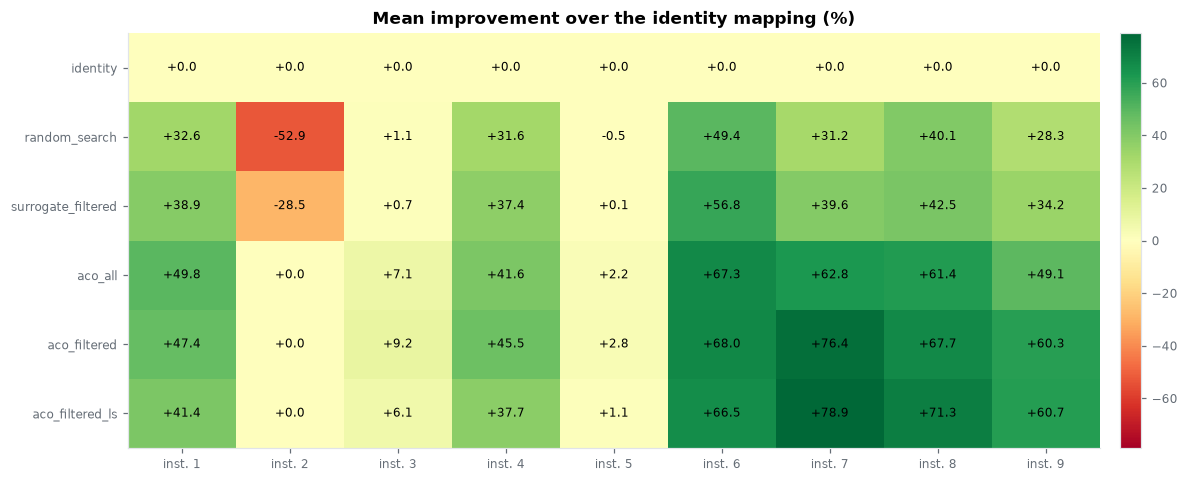

In [22]:
def gain_table(frame, reference="identity"):
    """Gain moyen de chaque algorithme par rapport à la référence, en % : 100 × (référence − algorithme) / référence."""
    means = frame.groupby(["algorithm", "instance_id"])["best_cost"].mean().unstack()
    return (100 * (means.loc[reference] - means) / means.loc[reference]).round(1)


def plot_gain_heatmap(gains):
    """Carte de chaleur des gains : vert = mieux que l'identité, rouge = moins bien."""
    # Échelle symétrique autour de 0.
    limit = max(5.0, float(np.nanmax(np.abs(gains.values))))
    fig, ax = plt.subplots(figsize=(1.0 * gains.shape[1] + 3, 0.55 * gains.shape[0] + 1.6))
    image = ax.imshow(gains.values, cmap="RdYlGn", vmin=-limit, vmax=limit, aspect="auto")
    for (i, j), value in np.ndenumerate(gains.values):
        ax.text(j, i, f"{value:+.1f}", ha="center", va="center", fontsize=8)
    ax.set_xticks(range(gains.shape[1]), [f"inst. {c}" for c in gains.columns])
    ax.set_yticks(range(gains.shape[0]), gains.index)
    ax.grid(False)
    ax.set_title("Mean improvement over the identity mapping (%)")
    fig.colorbar(image, ax=ax, fraction=0.03, pad=0.02)
    return fig


gains = gain_table(frame).reindex(ORDER)
plot_gain_heatmap(gains);

**Classement** : rang de chaque algorithme par instance (1 = meilleure moyenne), puis rang moyen.

In [23]:
# Moyenne du meilleur coût par algorithme (lignes) et instance (colonnes).
means = frame.groupby(["algorithm", "instance_id"])["best_cost"].mean().unstack()
# Rang dans chaque colonne (1 = plus petite moyenne ; égalités = même rang).
ranks = means.rank(axis=0, method="min").rename(columns=lambda c: f"inst. {c}")
ranks["mean rank"] = ranks.mean(axis=1).round(2)
ranks = ranks.sort_values("mean rank")
ranks

instance_id,inst. 1,inst. 2,inst. 3,inst. 4,inst. 5,inst. 6,inst. 7,inst. 8,inst. 9,mean rank
algorithm,,,,,,,,,,
aco_filtered,2.0,1.0,1.0,1.0,1.0,1.0,2.0,2.0,2.0,1.44
aco_all,1.0,1.0,2.0,2.0,2.0,2.0,3.0,3.0,3.0,2.11
aco_filtered_ls,3.0,1.0,3.0,3.0,3.0,3.0,1.0,1.0,1.0,2.11
surrogate_filtered,4.0,5.0,5.0,4.0,4.0,4.0,4.0,4.0,4.0,4.22
random_search,5.0,6.0,4.0,5.0,6.0,5.0,5.0,5.0,5.0,5.11
identity,6.0,1.0,6.0,6.0,5.0,6.0,6.0,6.0,6.0,5.33


**Significativité.** Test de Mann-Whitney unilatéral : la *p-value* mesure la probabilité d'observer un tel écart si `aco_filtered` n'était pas meilleur que l'autre algorithme. Une valeur < 0,05 indique un avantage fiable. Avec peu de graines, le test manque de puissance : une valeur élevée ne prouve pas l'égalité.

In [24]:
def significance(frame, algorithm, others):
    """p-values du test de Mann-Whitney « algorithm est meilleur que other », par instance (lignes) et adversaire (colonnes)."""
    rows = {}
    for instance_id in sorted(frame["instance_id"].unique()):
        subset = frame[frame["instance_id"] == instance_id]
        target = subset.loc[subset["algorithm"] == algorithm, "best_cost"]
        rows[f"inst. {instance_id}"] = {
            # alternative="less" : on teste si les coûts de `algorithm` sont plus petits.
            other: stats.mannwhitneyu(target, subset.loc[subset["algorithm"] == other, "best_cost"], alternative="less").pvalue
            for other in others
        }
    return pd.DataFrame(rows).T.round(4)


p_values = significance(frame, "aco_filtered", ["identity", "random_search", "surrogate_filtered", "aco_all"])
p_values

,identity,random_search,surrogate_filtered,aco_all
inst. 1,0.0035,0.0058,0.0057,0.5888
inst. 2,1.0000,0.0036,0.0037,1.0000
inst. 3,0.0037,0.0139,0.0078,0.1729
inst. 4,0.0036,0.0047,0.0096,0.0663
inst. 5,0.0055,0.0694,0.0181,0.2979
inst. 6,0.0028,0.0036,0.0037,0.2119
inst. 7,0.0036,0.0060,0.0058,0.0058
inst. 8,0.0053,0.0060,0.0060,0.0289
inst. 9,0.0035,0.0058,0.0058,0.0058


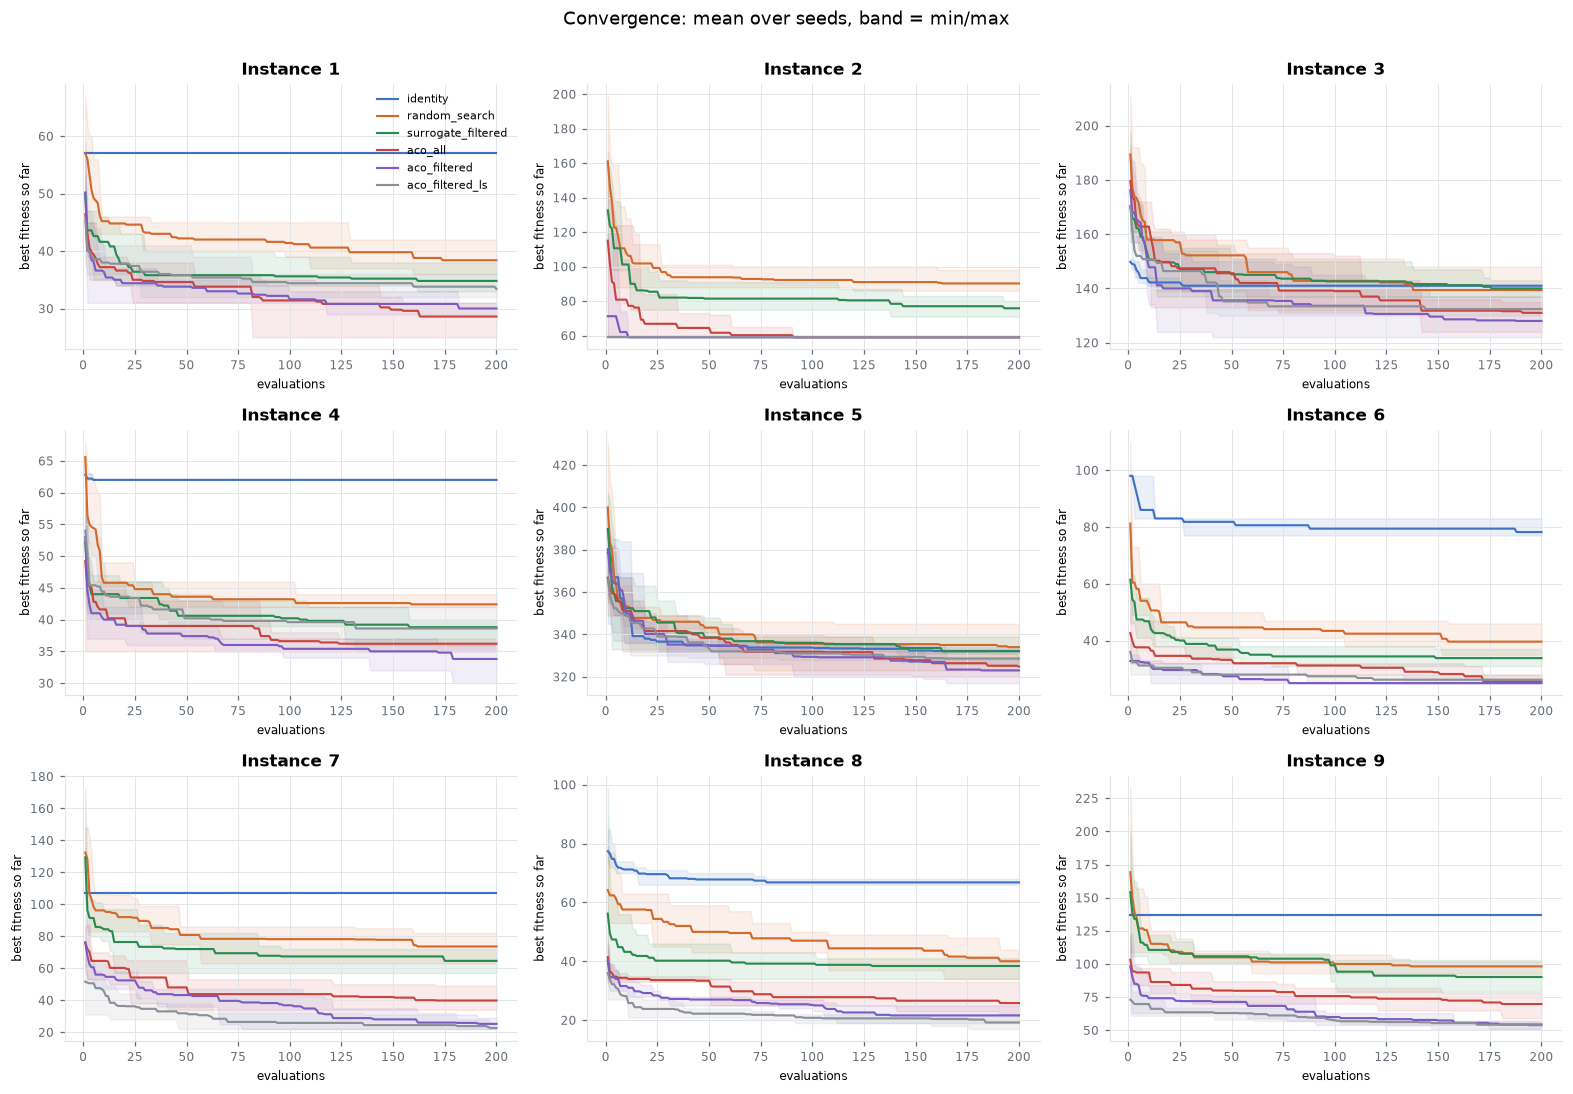

In [25]:
def plot_convergence(results, order):
    """Courbes de convergence de chaque algorithme sur chaque instance (moyenne sur les graines, bande min/max)."""
    history = history_frame(results)
    instance_ids = sorted(history["instance_id"].unique())
    fig, axes = subplot_grid(len(instance_ids), cols=3, width=4.8, height=3.3)
    for ax, instance_id in zip(axes, instance_ids):
        subset = history[history["instance_id"] == instance_id]
        for color, algorithm in zip(PALETTE, order):
            curves = subset[subset["algorithm"] == algorithm].pivot_table(index="evaluation", columns="seed", values="best").ffill()
            ax.plot(curves.index, curves.mean(axis=1), color=color, label=algorithm, linewidth=1.4)
            ax.fill_between(curves.index, curves.min(axis=1), curves.max(axis=1), color=color, alpha=0.1)
        ax.set_title(f"Instance {instance_id}")
        ax.set_xlabel("evaluations", fontsize=8)
        ax.set_ylabel("best fitness so far", fontsize=8)
    axes[0].legend(fontsize=7)
    fig.suptitle("Convergence: mean over seeds, band = min/max", y=1.0)
    fig.tight_layout()
    return fig


plot_convergence(comparison, ORDER);

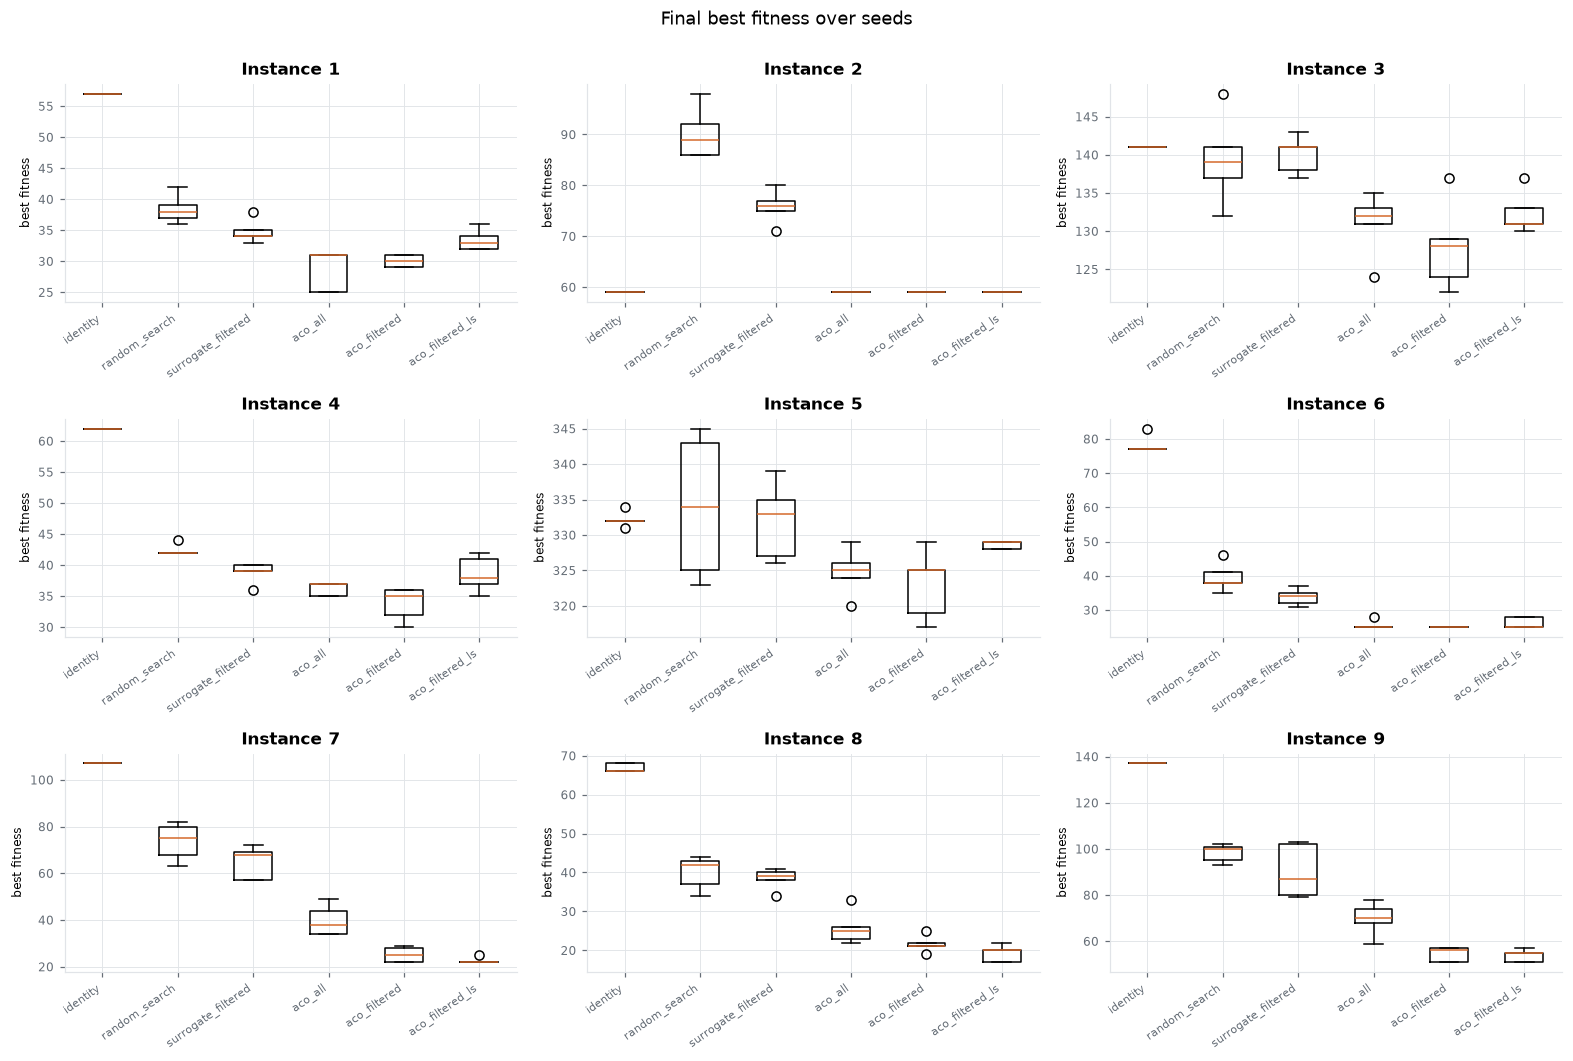

In [26]:
def plot_result_boxplots(frame, order):
    """Boîtes à moustaches du meilleur coût final, par instance et par algorithme."""
    instance_ids = sorted(frame["instance_id"].unique())
    fig, axes = subplot_grid(len(instance_ids), cols=3, width=4.8, height=3.2)
    for ax, instance_id in zip(axes, instance_ids):
        subset = frame[frame["instance_id"] == instance_id]
        ax.boxplot([subset.loc[subset["algorithm"] == a, "best_cost"] for a in order], widths=0.5, medianprops={"color": LOGICAL})
        ax.set_xticks(range(1, len(order) + 1), order, rotation=35, ha="right", fontsize=7)
        ax.set_title(f"Instance {instance_id}")
        ax.set_ylabel("best fitness", fontsize=8)
    fig.suptitle("Final best fitness over seeds", y=1.0)
    fig.tight_layout()
    return fig


plot_result_boxplots(frame, ORDER);

**Temps moyen d'une exécution** (secondes, pour le budget complet) : presque tout le temps est passé dans `fitness_inner` ; la construction des fourmis et la recherche locale sur le coût de distance sont négligeables.

In [27]:
run_times = frame.groupby(["algorithm", "instance_id"])["seconds"].mean().unstack().reindex(ORDER).round(1).rename(columns=lambda c: f"inst. {c}")
run_times

instance_id,inst. 1,inst. 2,inst. 3,inst. 4,inst. 5,inst. 6,inst. 7,inst. 8,inst. 9
algorithm,,,,,,,,,
identity,32.1,109.8,58.8,30.5,78.7,42.4,44.7,51.0,47.5
random_search,34.1,158.0,72.5,37.5,92.6,47.9,52.3,56.2,55.2
surrogate_filtered,31.1,139.1,59.3,29.7,80.9,40.9,43.1,48.6,51.7
aco_all,32.5,137.8,63.7,33.2,86.5,45.1,41.3,43.5,42.7
aco_filtered,32.1,133.8,59.3,37.8,95.2,45.7,40.8,48.9,47.0
aco_filtered_ls,45.0,131.2,73.4,33.3,57.3,22.9,19.1,24.3,22.8


## 5. Meilleures solutions

Pour chaque instance : le meilleur placement trouvé par les variantes ACO, réévalué `REEVALUATIONS` fois pour estimer sa vraie qualité (le coût enregistré pendant la recherche peut être un tirage chanceux). Le fichier `GROUP_Challenge_N.txt` est écrit dans `solutions/` avec le meilleur coût observé, **seulement s'il est meilleur** que la solution déjà enregistrée (une meilleure solution trouvée ailleurs n'est jamais écrasée). Il apparaît dans le visualiseur web et peut être affiché dans `00_instance_explorer`.

In [28]:
rows = []
for instance_id in COMPARISON_INSTANCES:
    # Toutes les exécutions ACO sur cette instance, et la meilleure d'entre elles.
    runs = [r for r in comparison if r.instance_id == instance_id and r.algorithm.startswith("aco")]
    best = min(runs, key=lambda r: r.best_cost)
    # Réévaluations du meilleur placement.
    checks = Problem(load_instance(instance_id)).fitness_samples(best.best_mapping, REEVALUATIONS)
    # Meilleur coût observé pour ce placement (pendant la recherche ou pendant les réévaluations).
    cost = min(best.best_cost, min(checks))
    path, written, previous = write_solution_if_better(best.best_mapping, cost, instance_id, group=GROUP, directory=SOLUTIONS_DIR)
    identity_mean = frame[(frame["instance_id"] == instance_id) & (frame["algorithm"] == "identity")]["best_cost"].mean()
    rows.append({
        "instance": instance_id,
        "algorithm": best.algorithm,
        "seed": best.seed,
        "cost during search": best.best_cost,
        "re-evaluation min": min(checks),
        "re-evaluation mean": round(float(np.mean(checks)), 2),
        "re-evaluation std": round(float(np.std(checks)), 2),
        "identity (best of budget)": round(float(identity_mean), 1),
        "file": path.name,
        "file status": "written" if written else f"kept (existing cost {previous:g})",
        # Placement en texte pour un affichage lisible.
        "mapping": " ".join(map(str, best.best_mapping)),
    })
best_solutions = pd.DataFrame(rows).set_index("instance")
best_solutions

,algorithm,seed,cost during search,re-evaluation min,re-evaluation mean,re-evaluation std,identity (best of budget),file,file status,mapping
instance,,,,,,,,,,
1,aco_all,2,25,25,27.5,2.50,57.0,Groupe0_Challenge_1.txt,kept (existing cost 25),0 14 13 2 12 3 11 15 4 10 5 1
2,aco_all,0,59,59,59.0,0.00,59.0,Groupe0_Challenge_2.txt,kept (existing cost 59),10 11 12 13 14 15 0 1 2 3 4 5 6 7 8 9
3,aco_filtered,0,122,122,140.3,7.47,141.0,Groupe0_Challenge_3.txt,kept (existing cost 122),6 9 10 7 12 3 4 11 8 5
4,aco_filtered,3,30,30,31.2,1.47,62.0,Groupe0_Challenge_4.txt,kept (existing cost 30),7 8 12 6 1 16 14 4 13 2 10 18 11 3 0 19 9 5 17
5,aco_filtered,1,317,335,337.1,4.66,332.2,Groupe0_Challenge_5.txt,kept (existing cost 315),5 6 8 7 16 17 11 14 10 12 13 18
6,aco_all,0,25,25,25.0,0.00,78.2,Groupe0_Challenge_6.txt,kept (existing cost 25),1 13 8 3 11 10 5 16 9 14 6 2 18 7
7,aco_filtered,0,22,22,22.0,0.00,107.0,Groupe0_Challenge_7.txt,kept (existing cost 22),9 8 5 3 2 1 4 7 12 10 13 14 16 19 22 24 25 23 ...
8,aco_filtered_ls,0,17,17,18.0,2.00,66.8,Groupe0_Challenge_8.txt,kept (existing cost 17),14 13 23 24 10 12 3 5 19 22 25 8 21 15 18 2 16...
9,aco_filtered,0,51,51,53.7,2.10,137.0,Groupe0_Challenge_9.txt,kept (existing cost 43),6 13 18 21 23 24 25 26 22 19 16 14 11 8 5 3 2 ...


## Conclusions

_Comparaison exécutée le 12/11/2026 : budget de 200 évaluations, 5 graines, 9 instances. Les chiffres bougent un peu d'une exécution à l'autre (bruit de la fitness, graines), les tendances non._

### La colonie de fourmis bat nettement les références

- `aco_filtered` a le **meilleur rang moyen (1,44)** : 1re sur 5 instances (2 à 6, ex æquo sur la 2), 2e sur les 4 autres. Sur l'instance 1, c'est `aco_all` qui fait le mieux ; sur 7, 8 et 9, c'est `aco_filtered_ls`.
- `aco_filtered` bat `surrogate_filtered` de façon significative (p < 0,05) sur les 9 instances, et `random_search` sur 8 instances sur 9 (l'instance 5 donne p ≈ 0,07).
- Gains moyens d'`aco_filtered` par rapport à l'identité :

| Instance | Identité | `aco_filtered` | Gain |
|---|---|---|---|
| 7 (GHZ chaîne) | 107,0 | 25,2 | −76 % |
| 6 (QAOA) | 78,2 | 25,0 | −68 % |
| 8 (état graphe) | 66,8 | 21,6 | −68 % |
| 9 (GHZ chaîne) | 137,0 | 54,4 | −60 % |
| 1 (Deutsch-Jozsa) | 57,0 | 30,0 | −47 % |
| 4 (GHZ étoile) | 62,0 | 33,8 | −45 % |
| 3 (QFT) | 141,0 | 128,0 | −9 % |
| 5 (Toffoli) | 332,2 | 323,0 | −3 % |
| 2 (chaîne ZZ) | 59,0 | 59,0 | 0 % |

Sur l'instance 2, toutes les variantes ACO retrouvent 59, comme l'identité, qui suit déjà la chaîne de la puce : c'est probablement l'optimum ou presque.

### Ce qui fait marcher la colonie (études de paramètres, instances 3 et 9)

- **L'heuristique est indispensable** : avec β = 0 (phéromones seules), l'instance 9 reste à 95 ; avec β = 2 à 4, elle descend à 53–56.
- **ρ = 0,2 est le meilleur compromis** sur les deux instances (122,3 et 52,0) : ρ = 0,05 apprend trop lentement, ρ = 0,4 se fige trop tôt.
- **Le filtrage par coût de distance est le gain principal** : `30/5` et `60/5` battent `10/10` et `20/20` (instance 9 : ≈ 54 contre ≈ 70). À budget égal, il permet 4 à 6 fois plus d'itérations. Dans la comparaison, `aco_filtered` bat `aco_all` de façon significative sur 7, 8 et 9.
- **La recherche locale sur le coût de distance n'aide que là où ce coût est fiable** : `aco_filtered_ls` est la meilleure sur 7, 8 et 9 (ρ de Spearman ≥ 0,74 au notebook 02), mais seulement 3e sur 1, 3, 4 et 5, où elle pousse vers des placements à faible coût de distance qui ne sont pas meilleurs en vraie fitness. C'est exactement ce que prédisait le notebook 02.

### Limites

- **Instances 3 et 5** : gains faibles. Le coût de distance y guide mal, et l'heuristique η repose sur ce même coût.
- **Bruit et « malédiction du gagnant »** : le meilleur coût enregistré est le minimum de nombreuses évaluations bruitées, donc optimiste. La section 5 le montre : sur l'instance 3, le meilleur placement a obtenu 122 pendant la recherche mais ≈ 141 en moyenne à la réévaluation ; sur l'instance 5, 317 contre ≈ 334 ; écarts plus faibles sur 1 et 4. Sur 2, 6, 7, 8 et 9, la solution est stable.
- **Temps** : une exécution de 200 évaluations prend de 20 s à 2,5 min selon l'instance, presque entièrement dans `fitness_inner`.

### Pistes d'amélioration

1. **Choisir la solution finale par réévaluation** : réévaluer les k meilleurs candidats plusieurs fois et garder la meilleure moyenne, plutôt que le minimum d'une seule évaluation.
2. **Pour 3 et 5** : moins se fier au coût de distance (filtrage moins sélectif, par exemple `30/15`, pas de recherche locale), ou finir le budget par une recherche locale sur la vraie fitness autour de la meilleure solution.
3. **Plus de budget** là où les courbes descendent encore à 200 évaluations (1, 3, 4, 7, 8).
4. **Comparer avec d'autres métaheuristiques** dans le même cadre : `run_grid`, même budget, mêmes graines.